# EDA: Online Shoppers Purchasing Intention

Objetivo: entender o dataset antes da modelagem e justificar as decisões do pipeline
(limpeza, tratamento das features, métrica e limiar). Cada seção termina com a
**implicação** para o projeto.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import precision_score, recall_score

from shopper_intent.config import load_params
from shopper_intent.data.preprocess import Preprocessor, split_features_target
from shopper_intent.features.build_features import FeatureBuilder
from shopper_intent.models.factory import ModelFactory
from shopper_intent.models.validation import CrossValidation

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PARAMS = load_params(ROOT / "params.yaml")

# Paleta de referência (validada para daltonismo); texto sempre em tons neutros.
SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK_MUTED,
        "xtick.color": INK_MUTED,
        "ytick.color": INK_MUTED,
        "text.color": INK,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.axisbelow": True,
        "font.size": 11,
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "figure.dpi": 110,
    }
)

raw = pd.read_csv(ROOT / PARAMS["data"]["raw_path"])
raw.shape

(12330, 18)

## 1. Qualidade dos dados

In [2]:
quality = pd.DataFrame({"tipo": raw.dtypes.astype(str), "nulos": raw.isna().sum()})
print(f"Linhas: {len(raw):,} | colunas: {raw.shape[1]} | duplicadas: {raw.duplicated().sum()}")
quality.T

Linhas: 12,330 | colunas: 18 | duplicadas: 125


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
tipo,int64,float64,int64,float64,int64,float64,float64,float64,float64,float64,object,int64,int64,int64,int64,object,bool,bool
nulos,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


**Implicação:** não há valores nulos, então o pipeline dispensa imputação. As 125 linhas
duplicadas são removidas **antes** do split (`Preprocessor.remove_duplicates`), senão a
mesma sessão poderia cair no treino e no teste, inflando a métrica.

## 2. Alvo: quantas sessões compram?

In [3]:
df = Preprocessor().cast_types(Preprocessor().remove_duplicates(raw))
conversion = df["Revenue"].mean()
print(f"Taxa de conversão: {conversion:.1%} ({df['Revenue'].sum():,} de {len(df):,} sessões)")
print(f"Acurácia de um modelo que sempre diz 'não compra': {1 - conversion:.1%}")

Taxa de conversão: 15.6% (1,908 de 12,205 sessões)
Acurácia de um modelo que sempre diz 'não compra': 84.4%


**Implicação:** a base é **desbalanceada** (~15,6% de compras). A acurácia engana: um
modelo inútil chega a ~84%. Por isso:
- split **estratificado** (`StratifiedSplitter`) e validação cruzada estratificada;
- `class_weight="balanced"` nos candidatos;
- métrica principal **PR-AUC** (`average_precision`), que foca na classe rara.

## 3. `PageValues`: o sinal mais forte

In [4]:
has_value = df["PageValues"] > 0
summary = df.groupby(has_value)["Revenue"].agg(sessoes="size", conversao="mean")
summary.index = ["PageValues = 0", "PageValues > 0"]
summary.style.format({"conversao": "{:.1%}", "sessoes": "{:,}"})

,sessoes,conversao
PageValues = 0,"9,475",3.9%
PageValues > 0,"2,730",56.3%


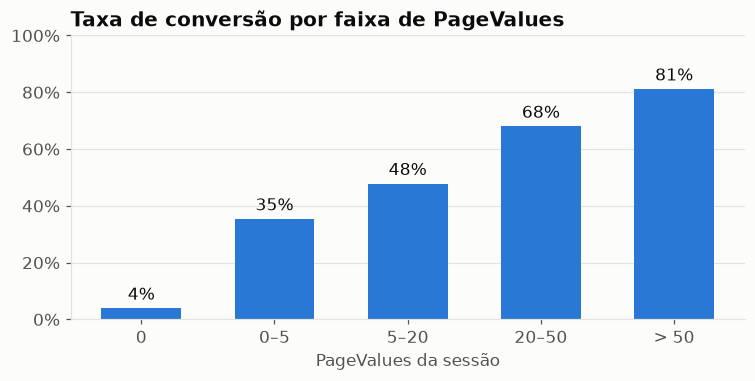

In [5]:
bins = [-0.01, 0, 5, 20, 50, df["PageValues"].max()]
labels = ["0", "0–5", "5–20", "20–50", "> 50"]
by_bucket = df.groupby(pd.cut(df["PageValues"], bins=bins, labels=labels), observed=True)
rate = by_bucket["Revenue"].mean()

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(rate.index.astype(str), rate.values, color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in rate.values], padding=3, color=INK)
ax.set_title("Taxa de conversão por faixa de PageValues")
ax.set_xlabel("PageValues da sessão")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylim(0, 1)
ax.grid(axis="x", visible=False)
plt.tight_layout()

**Implicação:** sessões com `PageValues = 0` quase nunca compram; acima de zero a
conversão salta. É a feature mais preditiva, mas exige cuidado: `PageValues` é a média
do valor das páginas visitadas **antes de uma transação** (métrica do Google Analytics).
Se, em produção, ela só fica disponível depois que a compra acontece, o modelo estaria
usando o próprio resultado (*data leakage*). A seção 7 mede o quanto o modelo depende
dela.

## 4. Sazonalidade: conversão por mês

Month,Feb,Mar,May,June,Jul,Aug,Sep,Oct,Nov,Dec
conversao,0.016575,0.103226,0.109643,0.101754,0.152778,0.17552,0.191964,0.209472,0.254863,0.126612
sessoes,181.000000,1860.000000,3329.000000,285.000000,432.000000,433.00000,448.000000,549.000000,2982.000000,1706.000000


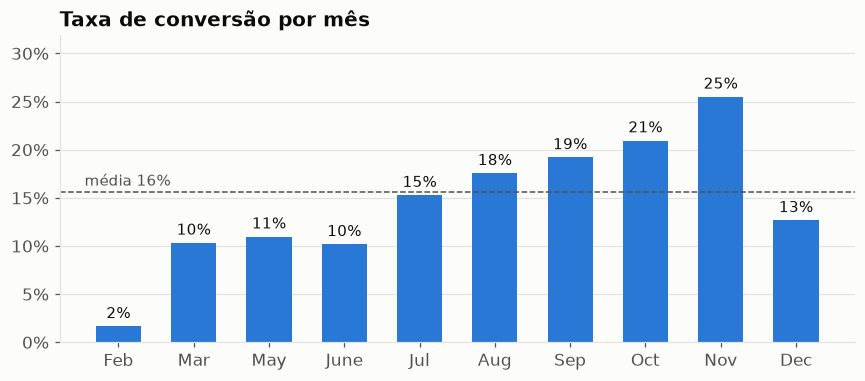

In [6]:
month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
by_month = df.groupby("Month")["Revenue"].agg(["mean", "size"]).reindex(month_order)

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(by_month.index, by_month["mean"], color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in by_month["mean"]], padding=3, color=INK, fontsize=10)
ax.axhline(conversion, color=INK_MUTED, linewidth=1, linestyle="--")
ax.annotate(
    f"média {conversion:.0%}",
    (-0.45, conversion),
    xytext=(0, 4),
    textcoords="offset points",
    ha="left",
    color=INK_MUTED,
    fontsize=10,
)
ax.set_title("Taxa de conversão por mês")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylim(0, by_month["mean"].max() * 1.25)
ax.grid(axis="x", visible=False)
plt.tight_layout()
by_month.rename(columns={"mean": "conversao", "size": "sessoes"}).T

**Implicação:** a conversão sobe ao longo do segundo semestre, com pico em novembro
(Black Friday); fevereiro é o mês mais fraco, e jan/abr não existem no dataset. `Month` entra como **categórica (One-Hot)**; o `OneHotEncoder` usa
`handle_unknown="ignore"`, então a API aceita "Jan"/"Apr" sem quebrar.

## 5. Tipo de visitante

In [7]:
by_visitor = df.groupby("VisitorType")["Revenue"].agg(conversao="mean", sessoes="size")
by_visitor.sort_values("conversao", ascending=False).style.format(
    {"conversao": "{:.1%}", "sessoes": "{:,}"}
)

,conversao,sessoes
VisitorType,,
New_Visitor,24.9%,"1,693"
Other,19.8%,81
Returning_Visitor,14.1%,"10,431"


**Implicação:** visitantes novos convertem mais que os recorrentes, embora sejam minoria.
`VisitorType` entra como categórica. O mesmo vale para `OperatingSystems`, `Browser`,
`Region` e `TrafficType`: são **códigos numéricos sem ordem**, então vão para o One-Hot,
e não para o `StandardScaler`.

## 6. Correlação das numéricas com a compra

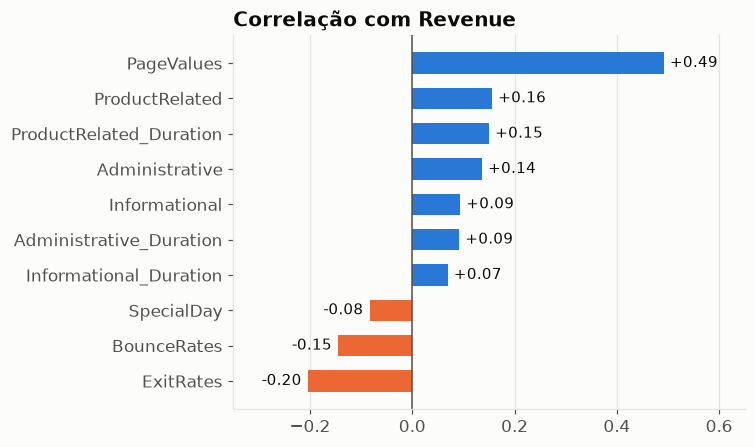

In [8]:
numeric = PARAMS["features"]["numeric"]
corr = df[numeric + ["Revenue"]].corr()["Revenue"].drop("Revenue").sort_values()

fig, ax = plt.subplots(figsize=(7, 4.2))
colors = [ORANGE if v < 0 else BLUE for v in corr.values]
ax.barh(corr.index, corr.values, color=colors, height=0.6)
for y, v in enumerate(corr.values):
    ax.annotate(
        f"{v:+.2f}",
        (v, y),
        xytext=(4 if v >= 0 else -4, 0),
        textcoords="offset points",
        ha="left" if v >= 0 else "right",
        va="center",
        color=INK,
        fontsize=10,
    )
ax.axvline(0, color=INK_MUTED, linewidth=1)
ax.set_title("Correlação com Revenue")
ax.set_xlim(-0.35, 0.65)
ax.grid(axis="y", visible=False)
plt.tight_layout()

Azul indica correlação positiva e laranja, negativa.

**Implicação:** além de `PageValues`, as durações e o volume de páginas de produto ajudam
positivamente; `ExitRates` e `BounceRates` (sessões que abandonam cedo) pesam contra. As
escalas são muito diferentes (durações chegam a 64 mil segundos), por isso as numéricas
passam pelo `StandardScaler`, importante para a regressão logística.

## 7. `PageValues`: sinal ou vazamento?

Mesma validação cruzada usada no estágio `train` (5 folds estratificados, só no treino),
com e sem a feature.

In [9]:
train = pd.read_csv(ROOT / PARAMS["data"]["train_path"])
x_train, y_train = split_features_target(train, PARAMS["data"]["target"])
features = PARAMS["features"]
cv = CrossValidation(PARAMS["train"]["cv_folds"], PARAMS["train"]["primary_metric"], PARAMS["seed"])


def cv_score(numeric_columns: list[str]) -> float:
    preprocessor = FeatureBuilder(numeric_columns, features["categorical"]).build()
    factory = ModelFactory(PARAMS["train"]["models"], PARAMS["seed"])
    pipeline = factory.create("hist_gradient_boosting", preprocessor)
    columns = numeric_columns + features["categorical"] + ["Weekend"]
    return cv.score(pipeline, x_train[columns], y_train)


without = [c for c in features["numeric"] if c != "PageValues"]
comparison = pd.Series(
    {"com PageValues": cv_score(features["numeric"]), "sem PageValues": cv_score(without)},
    name="CV PR-AUC",
)
comparison.to_frame().assign(base_aleatoria=y_train.mean()).round(3)

,CV PR-AUC,base_aleatoria
com PageValues,0.742,0.156
sem PageValues,0.378,0.156


**Implicação:** sem `PageValues` o PR-AUC cai para cerca de metade, embora continue acima
da base aleatória (a taxa de conversão). O modelo depende muito dessa feature. **Decisão:** mantê-la,
porque o enunciado trata o problema como propensão durante a navegação e o dataset a
fornece por sessão. Para produção, a pergunta a levar ao negócio é: *"o `PageValues` está
disponível no momento em que queremos prever?"* Se não estiver, o modelo sem ela é o
honesto.

## 8. Escolha do limiar (threshold)

Probabilidades do modelo `champion` (gravado pelo DVC em `models/model.pkl`) no conjunto de
**teste**. O limiar não muda o PR-AUC, mas decide quantas sessões são marcadas como
compradoras.

,precision,recall
0.100000,30.9%,99.0%
0.200000,37.5%,95.8%
0.300000,44.4%,90.8%
0.400000,49.5%,85.9%
0.500000,55.1%,80.9%
0.600000,59.6%,76.2%
0.700000,65.6%,72.3%
0.800000,70.3%,64.9%
0.900000,81.1%,46.1%


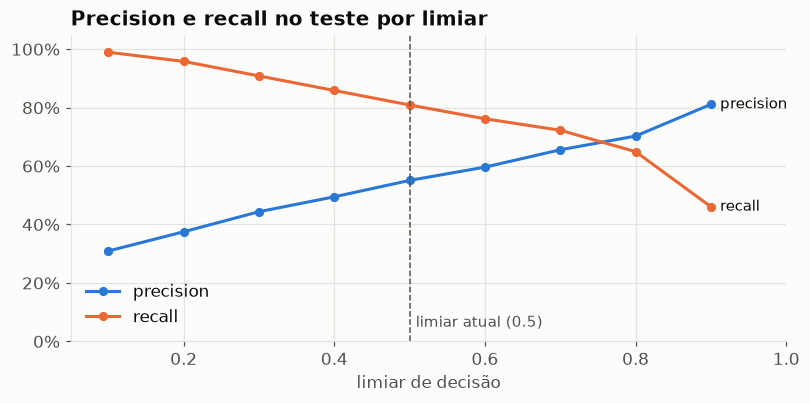

In [10]:
test = pd.read_csv(ROOT / PARAMS["data"]["test_path"])
x_test, y_test = split_features_target(test, PARAMS["data"]["target"])
proba = joblib.load(ROOT / PARAMS["train"]["model_path"]).predict_proba(x_test)[:, 1]

thresholds = [round(0.1 * i, 1) for i in range(1, 10)]
curve = pd.DataFrame(
    {
        "precision": [precision_score(y_test, proba >= t, zero_division=0) for t in thresholds],
        "recall": [recall_score(y_test, proba >= t) for t in thresholds],
    },
    index=thresholds,
)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for column, color in [("precision", BLUE), ("recall", ORANGE)]:
    ax.plot(curve.index, curve[column], color=color, linewidth=2, marker="o", markersize=5)
    ax.annotate(
        column,
        (curve.index[-1], curve[column].iloc[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        color=INK,
        fontsize=10,
    )
current = PARAMS["train"]["threshold"]
ax.axvline(current, color=INK_MUTED, linewidth=1, linestyle="--")
ax.annotate(
    f"limiar atual ({current})",
    (current, 0.05),
    xytext=(4, 0),
    textcoords="offset points",
    color=INK_MUTED,
    fontsize=10,
)
ax.set_title("Precision e recall no teste por limiar")
ax.set_xlabel("limiar de decisão")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylim(0, 1.05)
ax.set_xlim(0.05, 1.0)
ax.legend(["precision", "recall"], loc="lower left", frameon=False)
plt.tight_layout()
curve.style.format("{:.1%}")

**Implicação:** com `class_weight="balanced"`, o limiar 0,5 favorece o recall: o modelo
encontra a maior parte dos compradores ao custo de mais falsos positivos. Subir o limiar
troca recall por precisão. A escolha é de **negócio**: para um cupom barato, recall alto
compensa; para uma ação cara (ligação de vendas), vale um limiar maior. O limiar fica em
`params.yaml` (`train.threshold`), é logado em cada run e a API o lê do run do modelo
promovido.

## Resumo das decisões

| Achado | Decisão no pipeline |
|---|---|
| Sem nulos; 125 duplicadas | Remover duplicatas antes do split |
| Alvo desbalanceado (~15,6%) | Split e CV estratificados, `class_weight="balanced"`, PR-AUC |
| Códigos numéricos sem ordem | `OperatingSystems`, `Browser`, `Region`, `TrafficType` no One-Hot |
| Escalas muito diferentes | `StandardScaler` nas numéricas, dentro do `Pipeline` |
| Meses ausentes (jan/abr) | `handle_unknown="ignore"`; a API aceita os 12 meses |
| `PageValues` domina | Mantida; dependência medida e documentada |
| Trade-off precision × recall | Limiar configurável em `params.yaml`, logado no MLflow |